Device: cuda
✓ Loaded 280 results

Worst config: n=640, d_b=128, L=6, Test Acc=0.0796



100%|██████████| 170M/170M [00:02<00:00, 71.6MB/s]


Data loaded: Train=6400, Test=10000

Training: MLP
  Step     0 | Loss: 2.3040 | Acc: 0.1000
  Step  1000 | Loss: 1.2303 | Acc: 0.5216
  ⚠️  NaN encountered at step 1597 - recording collapse and stopping
  ⚠️  Using metrics from step 1500 (pre-collapse)
  ⚠️  Spectral analysis failed for mlp: linalg.svd: The algorithm failed to converge because the input matrix is ill-conditioned or has too many repeated singular values (error code: 10).
✓ MLP: Train=0.5841, Test=0.1000, Time=24.1s [COLLAPSED at step 1500]

Training: BATCHNORM


/tmp/ipykernel_23/2760048955.py:282: UserWarning: torch.linalg.svd: During SVD computation with the selected cusolver driver, batches 0 failed to converge. A more accurate method will be used to compute the SVD as a fallback. Check doc at https://pytorch.org/docs/stable/generated/torch.linalg.svd.html (Triggered internally at /pytorch/aten/src/ATen/native/cuda/linalg/BatchLinearAlgebraLib.cpp:702.)
  U, S, V = torch.svd(deepest_activation)


  Step     0 | Loss: 2.3984 | Acc: 0.1000
  Step  1000 | Loss: 0.0020 | Acc: 1.0000
  Step  2000 | Loss: 0.0026 | Acc: 1.0000
  Step  3000 | Loss: 0.0029 | Acc: 1.0000
  Step  4000 | Loss: 0.0030 | Acc: 1.0000
  Step  5000 | Loss: 0.0031 | Acc: 1.0000
  Step  6000 | Loss: 0.9536 | Acc: 0.4377
  Step  7000 | Loss: 0.0029 | Acc: 0.9998
✓ BATCHNORM: Train=0.9998, Test=0.2905, Time=106.1s

Training: RESNET
  Step     0 | Loss: 68.7320 | Acc: 0.1088
  Step  1000 | Loss: 0.0008 | Acc: 1.0000
  Step  2000 | Loss: 0.0010 | Acc: 1.0000
  Step  3000 | Loss: 0.0014 | Acc: 1.0000
  Step  4000 | Loss: 0.0019 | Acc: 1.0000
  Step  5000 | Loss: 0.0023 | Acc: 1.0000
✓ RESNET: Train=1.0000, Test=0.3927, Time=89.1s
✓ Saved: cure_rank_evolution.png
✓ Saved: cure_singular_spectra.png
✓ Saved: cure_training_curves.png

✅ COMPARATIVE PLOTS GENERATED:
  - cure_rank_evolution.png
  - cure_singular_spectra.png
  - cure_training_curves.png

✓ Saved: cure_test_accuracy.png
✓ Saved: cure_train_vs_test.png
✓ Saved

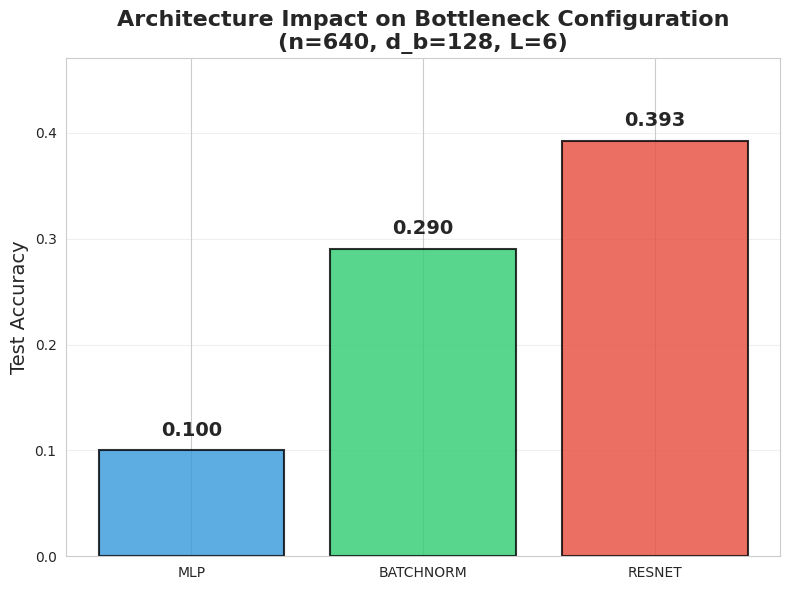

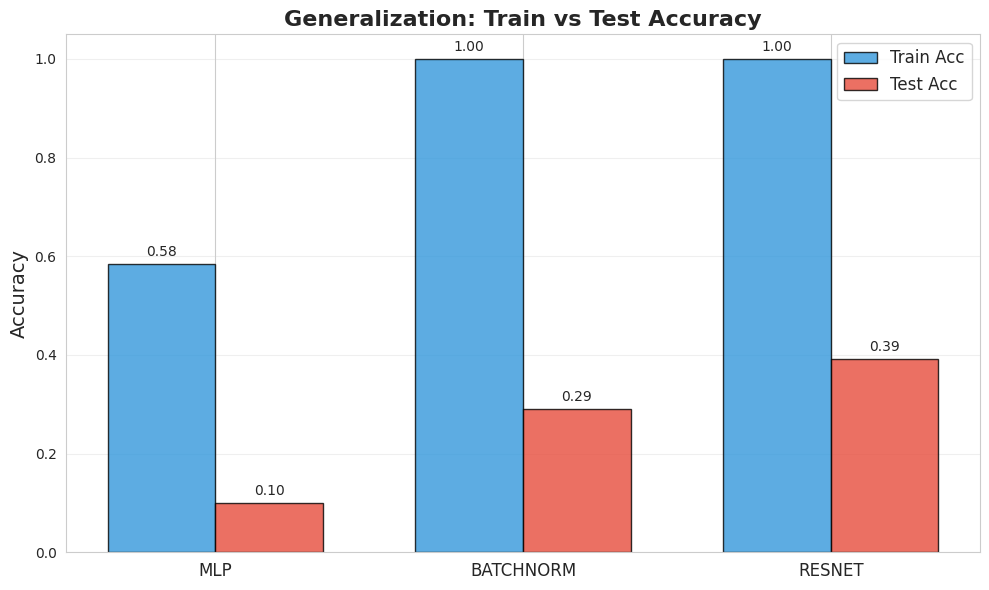

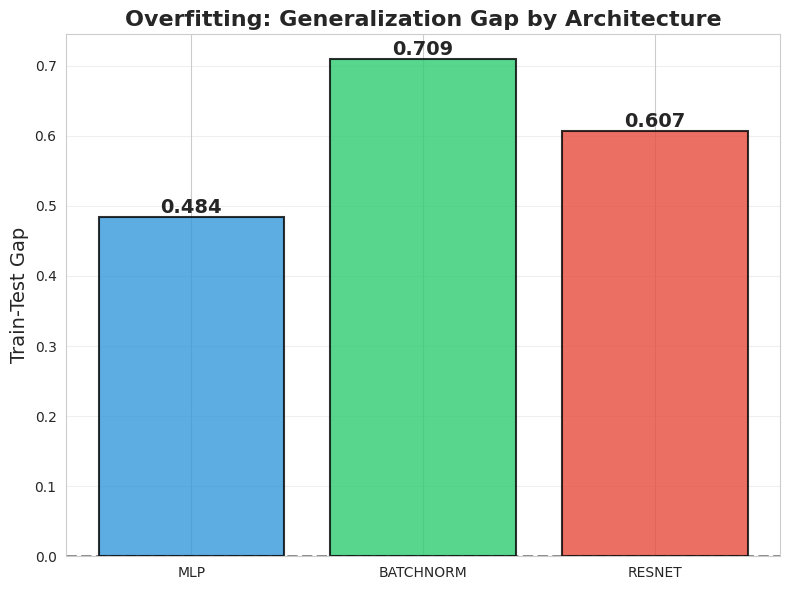

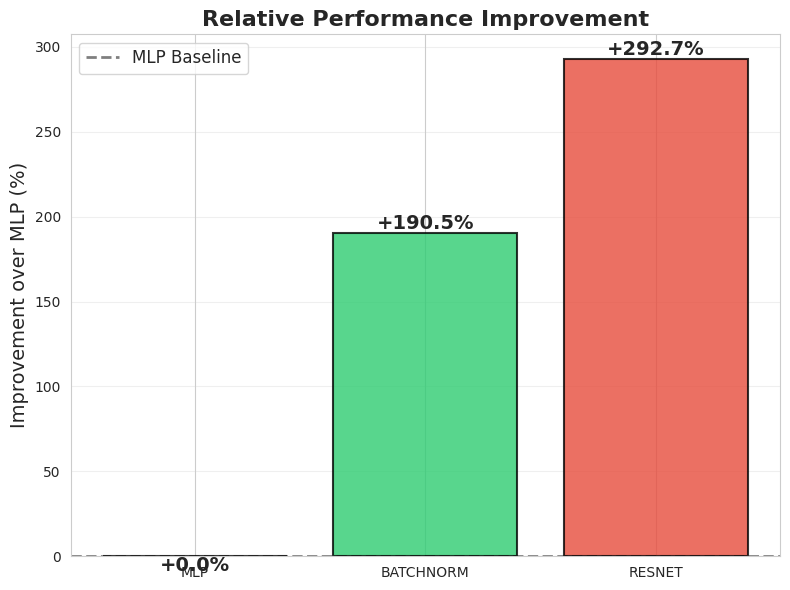

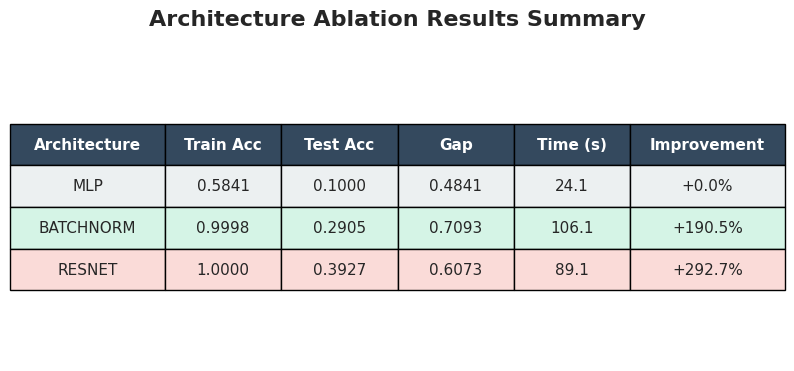

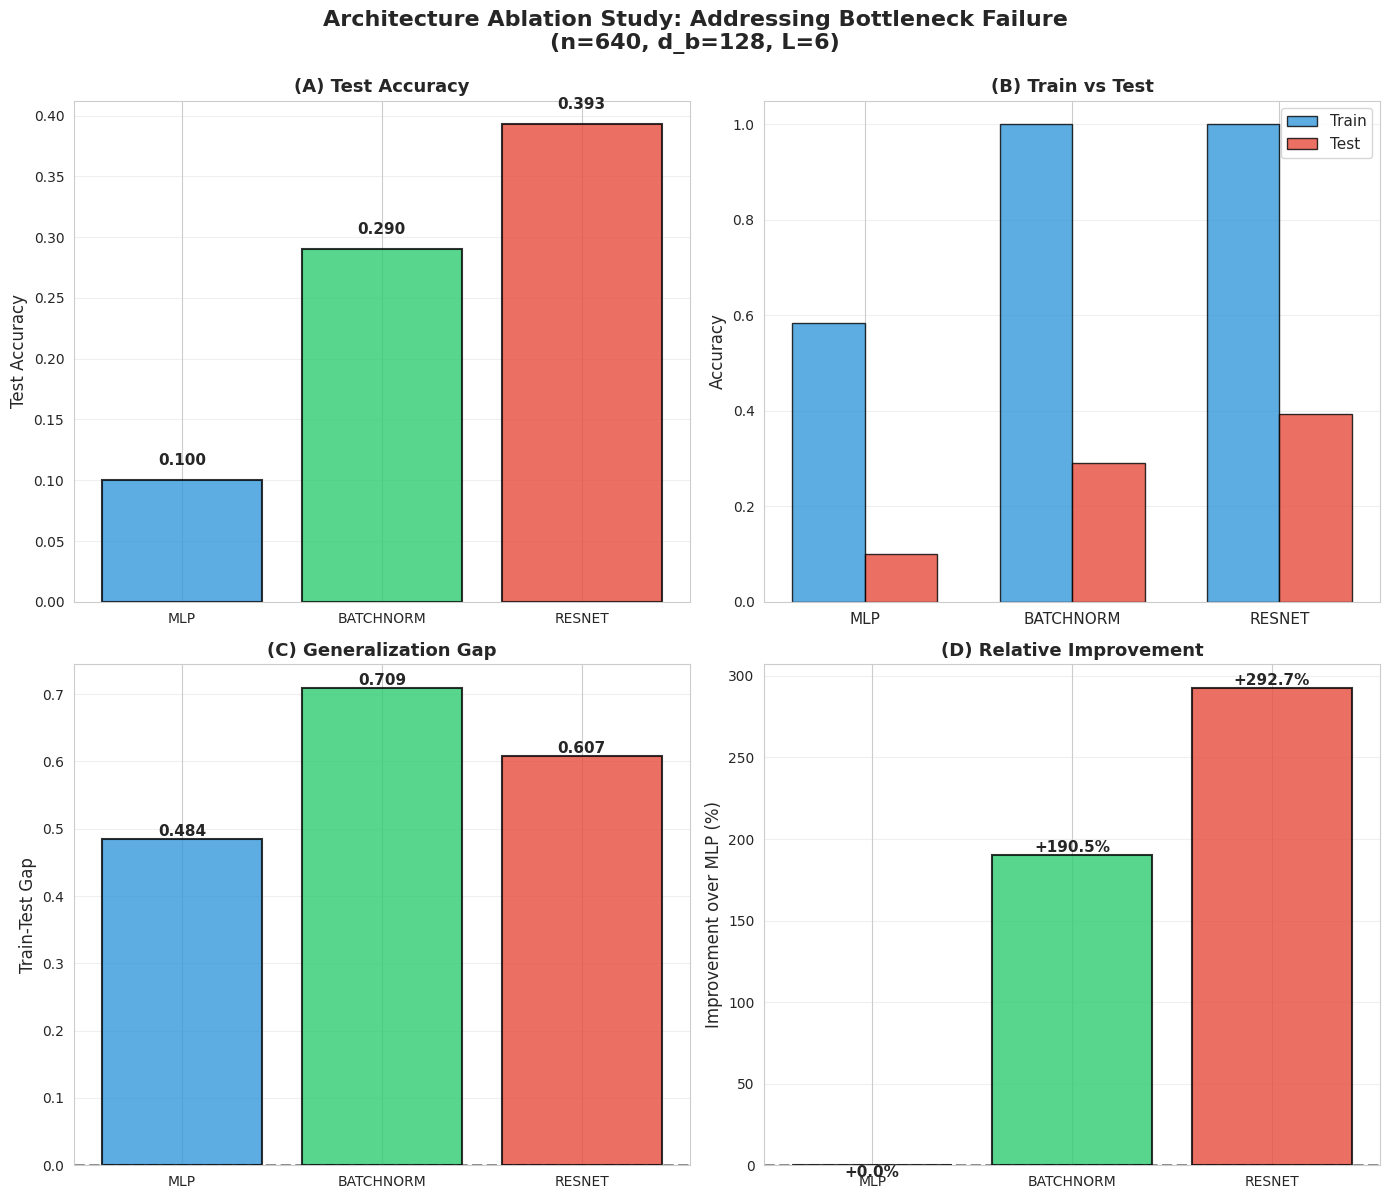

In [1]:
# %% CURE SWEEP ONLY - New Kaggle Notebook

import pickle
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import numpy as np
import pandas as pd
from pathlib import Path
from dataclasses import dataclass
import time

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")

# ============================================================================
# 1. LOAD CHECKPOINT TO GET WORST CONFIG
# ============================================================================

CHECKPOINT_PATH = Path('/kaggle/input/sweep-checkkpoint/sweep_checkpoint.pkl')  # UPDATE THIS

with open(CHECKPOINT_PATH, 'rb') as f:
    all_results = pickle.load(f)
print(f"✓ Loaded {len(all_results)} results")

worst_result = min(all_results, key=lambda r: r.get('final_test_acc', 0))
worst_config = worst_result['config']

print(f"\nWorst config: n={worst_config['n_per_class']}, d_b={worst_config['d_b']}, "
      f"L={worst_config['L_hidden']}, Test Acc={worst_result['final_test_acc']:.4f}\n")

# ============================================================================
# 2. ARCHITECTURE
# ============================================================================

class BottleneckMLP(nn.Module):
    def __init__(self, d0, K, L_hidden, d_b, arch_type='mlp'):
        super().__init__()
        self.arch_type = arch_type
        self.d_b = d_b
        self.L_hidden = L_hidden
        
        self.projector = nn.Sequential(nn.Linear(3072, d0), nn.ReLU())
        
        if arch_type == 'mlp':
            layers = [nn.Linear(d0, d_b), nn.ReLU()]
            for _ in range(L_hidden - 1):
                layers += [nn.Linear(d_b, d_b), nn.ReLU()]
            layers.append(nn.Linear(d_b, K))
            self.network = nn.Sequential(*layers)
            
        elif arch_type == 'batchnorm':
            layers = [nn.Linear(d0, d_b), nn.BatchNorm1d(d_b), nn.ReLU()]
            for _ in range(L_hidden - 1):
                layers += [nn.Linear(d_b, d_b), nn.BatchNorm1d(d_b), nn.ReLU()]
            layers.append(nn.Linear(d_b, K))
            self.network = nn.Sequential(*layers)
            
        elif arch_type == 'resnet':
            self.projection = nn.Linear(d0, d_b)
            self.residual_blocks = nn.ModuleList([nn.Linear(d_b, d_b) for _ in range(L_hidden)])
            self.output = nn.Linear(d_b, K)

            # ADD: Layer normalization for stability
            self.layer_norms = nn.ModuleList([nn.LayerNorm(d_b) for _ in range(L_hidden)])
    
    def forward(self, x):
        h = self.projector(x)
        
        if self.arch_type == 'resnet':
            h = self.projection(h)
            for block, norm in zip(self.residual_blocks, self.layer_norms):
                residual = h
                h = block(h)
                h = norm(h)  # ADD THIS
                h = torch.relu(h)
                h = h + residual
            return self.output(h)
        else:
            return self.network(h)

# ============================================================================
# 3. DATA
# ============================================================================

def load_data(n_per_class, train=True):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])
    
    dataset = torchvision.datasets.CIFAR10(root='./data', train=train, download=True, transform=transform)
    
    if train and n_per_class > 0:
        targets = np.array(dataset.targets)
        indices = []
        for k in range(10):
            class_idx = np.where(targets == k)[0]
            np.random.shuffle(class_idx)
            indices.extend(class_idx[:n_per_class])
        dataset = torch.utils.data.Subset(dataset, indices)
    
    loader = DataLoader(dataset, batch_size=len(dataset), shuffle=False)
    X, y = next(iter(loader))
    return X.view(len(X), -1).to(DEVICE), y.to(DEVICE)

X_train, y_train = load_data(worst_config['n_per_class'], train=True)
X_test, y_test = load_data(0, train=False)

print(f"Data loaded: Train={len(y_train)}, Test={len(y_test)}")

# ============================================================================
# 4. TRAIN FUNCTION
# ============================================================================

def train_arch(arch_type):
    print(f"\n{'='*60}\nTraining: {arch_type.upper()}\n{'='*60}")
    
    model = BottleneckMLP(
        d0=1000, K=10, L_hidden=worst_config['L_hidden'], 
        d_b=worst_config['d_b'], arch_type=arch_type
    ).to(DEVICE)
    
    # Initialization fixes (architecture-specific)
    if arch_type == 'resnet':
        for m in model.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
    
    # Architecture-specific hyperparameters (NO CLIPPING FOR MLP!)
    if arch_type == 'resnet':
        lr = 0.01
        use_grad_clip = True  # ResNet needs clipping
    elif arch_type == 'batchnorm':
        lr = 0.03
        use_grad_clip = False  # BatchNorm stabilizes itself
    else:  # mlp
        lr = 0.05
        use_grad_clip = False  # LET IT COLLAPSE - this is the point!
    
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=worst_config['wd'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100000)
    criterion = nn.CrossEntropyLoss()
    
    # === Track training history ===
    history = {'step': [], 'train_acc': [], 'loss': []}
    rank_history = {}
    
    nan_encountered = False
    last_valid_step = 0
    
    start = time.time()
    for step in range(100000):
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        
        # Handle NaN gracefully (record and stop)
        if torch.isnan(loss) or torch.isinf(loss):
            if not nan_encountered:
                print(f"  ⚠️  NaN encountered at step {step} - recording collapse and stopping")
                nan_encountered = True
                last_valid_step = max(history['step']) if history['step'] else 0
            break  # Stop training but preserve partial results
        
        loss.backward()
        
        # ONLY clip gradients for architectures that use it
        if use_grad_clip:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        scheduler.step()
        
        # === Log every 500 steps ===
        if step % 500 == 0:
            model.eval()
            with torch.no_grad():
                acc = (model(X_train).argmax(1) == y_train).float().mean().item()
                history['step'].append(step)
                history['train_acc'].append(acc)
                history['loss'].append(loss.item())
                
                # Extract activations for rank computation (every 2000 steps)
                if step % 2000 == 0:
                    h = model.projector(X_train)
                    if arch_type == 'resnet':
                        h = model.projection(h)
                        activations = [h]
                        for block, norm in zip(model.residual_blocks, model.layer_norms):
                            residual = h
                            h = block(h)
                            h = norm(h)
                            h = torch.relu(h)
                            h = h + residual
                            activations.append(h)
                    else:
                        activations = []
                        for layer in model.network:
                            h = layer(h)
                            if isinstance(layer, nn.Linear):
                                activations.append(h)
                    
                    # Compute stable ranks (FIXED: scientific rigor)
                    step_ranks = []
                    for idx, act in enumerate(activations[:-1]):
                        if len(act.shape) == 2 and act.shape[0] > 1:
                            try:
                                frob_sq = torch.norm(act, p='fro').item() ** 2
                                spec_sq = torch.linalg.matrix_norm(act, ord=2).item() ** 2
                                
                                # Dead signal check
                                if spec_sq < 1e-10:
                                    rank = 1.0
                                elif spec_sq > 0 and frob_sq > 0:
                                    rank = frob_sq / spec_sq
                                    rank = max(1.0, rank)
                                    if not np.isfinite(rank):
                                        rank = np.nan
                                else:
                                    rank = np.nan
                                    
                            except Exception as e:
                                rank = np.nan
                                
                            step_ranks.append(rank)
                    
                    rank_history[step] = step_ranks
            
            model.train()
            
            if step % 1000 == 0:
                print(f"  Step {step:5d} | Loss: {loss.item():.4f} | Acc: {acc:.4f}")
            
            if step > 5000 and loss.item() < 0.01:
                break
    
    # Final evaluation (handle NaN collapse gracefully)
    model.eval()
    with torch.no_grad():
        # If training collapsed, use last valid checkpoint metrics
        if nan_encountered:
            print(f"  ⚠️  Using metrics from step {last_valid_step} (pre-collapse)")
            train_acc = history['train_acc'][-1] if history['train_acc'] else np.nan
            # Test accuracy might still work even if training collapsed
            try:
                test_preds = model(X_test).argmax(1)
                test_acc = (test_preds == y_test).float().mean().item()
                if not np.isfinite(test_acc):
                    test_acc = np.nan
            except:
                test_acc = np.nan
        else:
            train_acc = (model(X_train).argmax(1) == y_train).float().mean().item()
            test_acc = (model(X_test).argmax(1) == y_test).float().mean().item()
        
        # Final spectra (deepest layer) - handle collapse
        try:
            h = model.projector(X_train)
            if arch_type == 'resnet':
                h = model.projection(h)
                for block, norm in zip(model.residual_blocks, model.layer_norms):
                    residual = h
                    h = block(h)
                    h = norm(h)
                    h = torch.relu(h)
                    h_pre_residual = h
                    h = h + residual
                deepest_activation = h_pre_residual
            else:
                for layer in model.network:
                    h = layer(h)
                    if isinstance(layer, nn.Linear):
                        deepest_activation = h
            
            # Compute SVD (FIXED: handle numerical errors)
            U, S, V = torch.svd(deepest_activation)
            singular_values = S.cpu().numpy()[:20]
            singular_values = np.where(np.isfinite(singular_values), singular_values, np.nan)
        except Exception as e:
            print(f"  ⚠️  Spectral analysis failed for {arch_type}: {e}")
            singular_values = np.full(20, np.nan)
    
    elapsed = time.time() - start
    
    # Add collapse flag to results
    result_dict = {
        'arch': arch_type, 
        'train_acc': train_acc, 
        'test_acc': test_acc, 
        'gap': train_acc - test_acc if np.isfinite(train_acc) and np.isfinite(test_acc) else np.nan,
        'time': elapsed,
        'history': history,
        'rank_history': rank_history,
        'singular_values': singular_values,
        'collapsed': nan_encountered,  # NEW: flag for catastrophic collapse
        'collapse_step': last_valid_step if nan_encountered else None
    }
    
    print(f"✓ {arch_type.upper()}: Train={train_acc:.4f}, Test={test_acc:.4f}, Time={elapsed:.1f}s" + 
          (f" [COLLAPSED at step {last_valid_step}]" if nan_encountered else ""))
    
    return result_dict

# ============================================================================
# 5. RUN CURE SWEEP
# ============================================================================

results = []
for arch in ['mlp', 'batchnorm', 'resnet']:
    results.append(train_arch(arch))

# ============================================================================
# NEW: COMPARATIVE PLOTS WITH ACTUAL DATA
# ============================================================================

import matplotlib.pyplot as plt

# Plot 1: Rank Evolution (FIXED: drop NaN values)
fig, ax = plt.subplots(figsize=(12, 8))
colors = {'mlp': 'red', 'batchnorm': 'blue', 'resnet': 'green'}
labels = {'mlp': 'Baseline MLP', 'batchnorm': 'BatchNorm', 'resnet': 'ResNet'}

for r in results:
    arch = r['arch']
    rank_hist = r['rank_history']
    
    if len(rank_hist) > 0:
        # Get final ranks (last checkpoint)
        final_step = max(rank_hist.keys())
        final_ranks = np.array(rank_hist[final_step])
        layers = np.arange(len(final_ranks))
        
        # Drop NaN values for plotting
        valid_mask = np.isfinite(final_ranks)
        if np.any(valid_mask):
            ax.plot(layers[valid_mask], final_ranks[valid_mask], 'o-', color=colors[arch], 
                    linewidth=3, markersize=10, label=labels[arch], alpha=0.9)

ax.axhline(y=1.0, color='black', linestyle='--', linewidth=2, alpha=0.5, label='Rank = 1 (Collapse)')
ax.set_xlabel('Layer Index', fontsize=14, fontweight='bold')
ax.set_ylabel('Stable Rank', fontsize=14, fontweight='bold')
ax.set_title(f'Rank Evolution Comparison (n={worst_config["n_per_class"]}, d_b={worst_config["d_b"]}, L={worst_config["L_hidden"]})', 
            fontsize=16, fontweight='bold')
ax.legend(fontsize=12, loc='best')
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig('cure_rank_evolution.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ Saved: cure_rank_evolution.png")

# Plot 2: Singular Spectra (FIXED: drop NaN values)
fig, ax = plt.subplots(figsize=(12, 8))
markers = {'mlp': 'o', 'batchnorm': 's', 'resnet': '^'}

for r in results:
    arch = r['arch']
    svals = r['singular_values']
    indices = np.arange(1, len(svals) + 1)
    
    # Drop NaN values for plotting
    valid_mask = np.isfinite(svals)
    if np.any(valid_mask):
        ax.loglog(indices[valid_mask], svals[valid_mask], marker=markers[arch], color=colors[arch], 
                 linewidth=2.5, markersize=8, label=labels[arch], alpha=0.9)

ax.set_xlabel('Singular Value Index (Log)', fontsize=14, fontweight='bold')
ax.set_ylabel('Singular Value Magnitude (Log)', fontsize=14, fontweight='bold')
ax.set_title('Singular Spectrum at Deepest Layer', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('cure_singular_spectra.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ Saved: cure_singular_spectra.png")

# Plot 3: Training Curves
fig, ax = plt.subplots(figsize=(14, 8))
linestyles = {'mlp': '-', 'batchnorm': '--', 'resnet': '-'}

for r in results:
    arch = r['arch']
    hist = r['history']
    ax.plot(hist['step'], hist['train_acc'], color=colors[arch], 
           linewidth=3, linestyle=linestyles[arch], label=labels[arch], alpha=0.8)

ax.axhline(y=0.1, color='gray', linestyle=':', linewidth=2, alpha=0.6, label='Random (10 classes)')
ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Training Accuracy', fontsize=14, fontweight='bold')
ax.set_title('Training Dynamics: MLP Collapse vs ResNet', fontsize=16, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 1.05])
plt.tight_layout()
plt.savefig('cure_training_curves.png', dpi=300, bbox_inches='tight')
plt.close()
print("✓ Saved: cure_training_curves.png")

print("\n" + "="*60)
print("✅ COMPARATIVE PLOTS GENERATED:")
print("  - cure_rank_evolution.png")
print("  - cure_singular_spectra.png")
print("  - cure_training_curves.png")
print("="*60 + "\n")

# ============================================================================
# PUBLICATION-QUALITY PLOTS
# ============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# Extract metrics for plotting
arch_names = [r['arch'].upper() for r in results]
test_accs = [r['test_acc'] for r in results]
train_accs = [r['train_acc'] for r in results]
gaps = [r['gap'] for r in results]

# ============================================================================
# PLOT 1: Test Accuracy Comparison (Main Result)
# ============================================================================

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
colors = ['#3498db', '#2ecc71', '#e74c3c']
bars = ax.bar(arch_names, test_accs, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for bar, acc in zip(bars, test_accs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{acc:.3f}', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.set_ylabel('Test Accuracy', fontsize=14)
ax.set_title('Architecture Impact on Bottleneck Configuration\n(n=640, d_b=128, L=6)', 
             fontsize=16, fontweight='bold')
ax.set_ylim([0, max(test_accs) * 1.2])
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('cure_test_accuracy.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cure_test_accuracy.png")

# ============================================================================
# PLOT 2: Train vs Test (Generalization)
# ============================================================================

fig, ax = plt.subplots(1, 1, figsize=(10, 6))

x = np.arange(len(arch_names))
width = 0.35

bars1 = ax.bar(x - width/2, train_accs, width, label='Train Acc', 
               color='#3498db', alpha=0.8, edgecolor='black')
bars2 = ax.bar(x + width/2, test_accs, width, label='Test Acc', 
               color='#e74c3c', alpha=0.8, edgecolor='black')

ax.set_ylabel('Accuracy', fontsize=14)
ax.set_title('Generalization: Train vs Test Accuracy', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(arch_names, fontsize=12)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.2f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('cure_train_vs_test.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cure_train_vs_test.png")

# ============================================================================
# PLOT 3: Generalization Gap
# ============================================================================

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
bars = ax.bar(arch_names, gaps, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

ax.axhline(y=0, color='black', linestyle='--', linewidth=2, alpha=0.5)
ax.set_ylabel('Train-Test Gap', fontsize=14)
ax.set_title('Overfitting: Generalization Gap by Architecture', fontsize=16, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bar, gap in zip(bars, gaps):
    height = bar.get_height()
    va = 'bottom' if gap > 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{gap:.3f}', ha='center', va=va, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('cure_generalization_gap.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cure_generalization_gap.png")

# ============================================================================
# PLOT 4: Improvement Over Baseline (MLP)
# ============================================================================

baseline_acc = results[0]['test_acc']  # MLP is first
improvements = [(r['test_acc'] - baseline_acc) / baseline_acc * 100 for r in results]

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
bars = ax.bar(arch_names, improvements, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

ax.axhline(y=0, color='black', linestyle='--', linewidth=2, alpha=0.5, label='MLP Baseline')
ax.set_ylabel('Improvement over MLP (%)', fontsize=14)
ax.set_title('Relative Performance Improvement', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bar, imp in zip(bars, improvements):
    height = bar.get_height()
    va = 'bottom' if imp > 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{imp:+.1f}%', ha='center', va=va, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('cure_improvement.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cure_improvement.png")

# ============================================================================
# PLOT 5: Summary Table (Publication-Ready)
# ============================================================================

fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.axis('tight')
ax.axis('off')

table_data = [
    ['Architecture', 'Train Acc', 'Test Acc', 'Gap', 'Time (s)', 'Improvement'],
]

for r, imp in zip(results, improvements):
    table_data.append([
        r['arch'].upper(),
        f"{r['train_acc']:.4f}",
        f"{r['test_acc']:.4f}",
        f"{r['gap']:.4f}",
        f"{r['time']:.1f}",
        f"{imp:+.1f}%"
    ])

table = ax.table(cellText=table_data, cellLoc='center', loc='center',
                colWidths=[0.2, 0.15, 0.15, 0.15, 0.15, 0.2])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.5)

# Style header
for i in range(6):
    table[(0, i)].set_facecolor('#34495e')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color code rows
for i in range(1, 4):
    for j in range(6):
        if i == 1:  # MLP
            table[(i, j)].set_facecolor('#ecf0f1')
        elif i == 2:  # BatchNorm
            table[(i, j)].set_facecolor('#d5f4e6')
        else:  # ResNet
            table[(i, j)].set_facecolor('#fadbd8')

plt.title('Architecture Ablation Results Summary', fontsize=16, fontweight='bold', pad=20)
plt.savefig('cure_summary_table.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cure_summary_table.png")

# ============================================================================
# PLOT 6: Combined 2x2 Figure (Main Paper Figure)
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Top-left: Test Accuracy
ax = axes[0, 0]
bars = ax.bar(arch_names, test_accs, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
for bar, acc in zip(bars, test_accs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{acc:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_title('(A) Test Accuracy', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Top-right: Train vs Test
ax = axes[0, 1]
x = np.arange(len(arch_names))
width = 0.35
ax.bar(x - width/2, train_accs, width, label='Train', color='#3498db', alpha=0.8, edgecolor='black')
ax.bar(x + width/2, test_accs, width, label='Test', color='#e74c3c', alpha=0.8, edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(arch_names, fontsize=11)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('(B) Train vs Test', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

# Bottom-left: Generalization Gap
ax = axes[1, 0]
bars = ax.bar(arch_names, gaps, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=0, color='black', linestyle='--', linewidth=2, alpha=0.5)
for bar, gap in zip(bars, gaps):
    height = bar.get_height()
    va = 'bottom' if gap > 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{gap:.3f}', ha='center', va=va, fontsize=11, fontweight='bold')
ax.set_ylabel('Train-Test Gap', fontsize=12)
ax.set_title('(C) Generalization Gap', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Bottom-right: Improvement
ax = axes[1, 1]
bars = ax.bar(arch_names, improvements, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=0, color='black', linestyle='--', linewidth=2, alpha=0.5)
for bar, imp in zip(bars, improvements):
    height = bar.get_height()
    va = 'bottom' if imp > 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{imp:+.1f}%', ha='center', va=va, fontsize=11, fontweight='bold')
ax.set_ylabel('Improvement over MLP (%)', fontsize=12)
ax.set_title('(D) Relative Improvement', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

fig.suptitle('Architecture Ablation Study: Addressing Bottleneck Failure\n(n=640, d_b=128, L=6)', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('cure_main_figure.png', dpi=300, bbox_inches='tight')
print("✓ Saved: cure_main_figure.png")

print("\n" + "="*60)
print("PUBLICATION PLOTS GENERATED:")
print("  1. cure_test_accuracy.png      - Bar chart (main result)")
print("  2. cure_train_vs_test.png      - Grouped bars")
print("  3. cure_generalization_gap.png - Overfitting metric")
print("  4. cure_improvement.png        - Relative gains")
print("  5. cure_summary_table.png      - Results table")
print("  6. cure_main_figure.png        - Combined 2×2 (MAIN PAPER FIGURE)")
print("="*60)


# ============================================================================
# 6. RESULTS
# ============================================================================

print("\n" + "="*60)
print("CURE SWEEP RESULTS")
print("="*60)

for r in sorted(results, key=lambda x: x['test_acc'], reverse=True):
    print(f"{r['arch'].upper():12} | Test: {r['test_acc']:.4f} | Gap: {r['gap']:.4f}")

print("="*60)

df = pd.DataFrame(results)
df.to_csv('cure_results.csv', index=False)
print("\n✓ Saved to cure_results.csv")


# ============================================================================
# SAVE COMPLETE EXPERIMENT DATA FOR RE-PLOTTING (NO RE-RUN NEEDED)
# ============================================================================

print("\n" + "="*60)
print("SAVING EXPERIMENT DATA FOR FUTURE RE-PLOTTING...")
print("="*60)

save_start = time.time()

# Prepare complete export data
export_data = {
    'metadata': {
        'experiment': 'CURE_sweep',
        'config': worst_config,
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
        'device': DEVICE
    },
    'results': results,  # Already contains history, rank_history, singular_values
    'plotting_data': {
        'arch_names': arch_names,
        'test_accs': test_accs,
        'train_accs': train_accs,
        'gaps': gaps,
        'improvements': improvements,
        'baseline_acc': baseline_acc
    }
}

# Save as pickle (preserves NaN, full precision)
with open('cure_complete_data.pkl', 'wb') as f:
    pickle.dump(export_data, f, protocol=pickle.HIGHEST_PROTOCOL)

# Save as CSV (human-readable, preserves NaN)
summary_df = pd.DataFrame({
    'architecture': arch_names,
    'train_acc': train_accs,
    'test_acc': test_accs,
    'generalization_gap': gaps,
    'improvement_pct': improvements,
    'training_time_sec': [r['time'] for r in results]
})
summary_df.to_csv('cure_summary.csv', index=False, na_rep='NaN')

# Save rank evolution data (wide format)
rank_data_rows = []
for r in results:
    arch = r['arch']
    for step, ranks in r['rank_history'].items():
        for layer_idx, rank_val in enumerate(ranks):
            rank_data_rows.append({
                'architecture': arch,
                'step': step,
                'layer': layer_idx,
                'stable_rank': rank_val  # NaN preserved
            })

rank_df = pd.DataFrame(rank_data_rows)
rank_df.to_csv('cure_rank_evolution.csv', index=False, na_rep='NaN')

# Save singular values
sv_data_rows = []
for r in results:
    arch = r['arch']
    for idx, sv in enumerate(r['singular_values'], 1):
        sv_data_rows.append({
            'architecture': arch,
            'singular_value_index': idx,
            'singular_value': sv  # NaN preserved
        })

sv_df = pd.DataFrame(sv_data_rows)
sv_df.to_csv('cure_singular_values.csv', index=False, na_rep='NaN')

# Save training curves
training_data_rows = []
for r in results:
    arch = r['arch']
    hist = r['history']
    for step, acc, loss in zip(hist['step'], hist['train_acc'], hist['loss']):
        training_data_rows.append({
            'architecture': arch,
            'step': step,
            'train_acc': acc,
            'loss': loss
        })

training_df = pd.DataFrame(training_data_rows)
training_df.to_csv('cure_training_curves.csv', index=False, na_rep='NaN')

save_elapsed = time.time() - save_start

print(f"\n DATA EXPORT COMPLETE (took {save_elapsed:.2f}s)")
print("="*60)
print("FILES SAVED:")
print("   cure_complete_data.pkl       - Full experiment data (pickle)")
print("   cure_summary.csv             - High-level results")
print("   cure_rank_evolution.csv      - Rank history by layer/step")
print("   cure_singular_values.csv     - Singular spectra")
print("   cure_training_curves.csv     - Training dynamics")
print("="*60)
print("\n TO RE-PLOT WITHOUT RE-RUNNING:")
print("   import pickle")
print("   with open('cure_complete_data.pkl', 'rb') as f:")
print("       data = pickle.load(f)")
print("   # Access: data['results'], data['plotting_data'], etc.")
print("="*60 + "\n")

# ============================================================================
# DATA VALIDATION REPORT
# ============================================================================

print("\n" + "="*60)
print("DATA QUALITY VALIDATION")
print("="*60)

for r in results:
    arch = r['arch'].upper()
    print(f"\n{arch}:")
    
    # NEW: Check for catastrophic collapse
    if r.get('collapsed', False):
        print(f"  ⚠️  CATASTROPHIC COLLAPSE at step {r['collapse_step']}")
        print(f"      This is EXPECTED for vanilla MLP in bottleneck regime!")
    
    # Check accuracies
    if np.isnan(r['train_acc']) or np.isnan(r['test_acc']):
        print(f"  ⚠️  WARNING: Accuracy contains NaN")
    else:
        print(f"  ✓ Accuracies valid: Train={r['train_acc']:.4f}, Test={r['test_acc']:.4f}")
    
    # Check rank history
    if len(r['rank_history']) > 0:
        all_ranks = []
        for step_ranks in r['rank_history'].values():
            all_ranks.extend(step_ranks)
        all_ranks = np.array(all_ranks)
        
        n_valid = np.sum(np.isfinite(all_ranks))
        n_nan = np.sum(np.isnan(all_ranks))
        
        if n_valid > 0:
            valid_ranks = all_ranks[np.isfinite(all_ranks)]
            min_rank = np.min(valid_ranks)
            max_rank = np.max(valid_ranks)
            
            if min_rank < 1.0:
                print(f"  ❌ ERROR: Found rank < 1.0 (min={min_rank:.4f})")
            else:
                print(f"  ✓ Ranks valid: range=[{min_rank:.2f}, {max_rank:.2f}], NaN={n_nan}/{len(all_ranks)}")
    
    # Check singular values
    svals = r['singular_values']
    n_valid_sv = np.sum(np.isfinite(svals))
    n_nan_sv = np.sum(np.isnan(svals))
    
    if n_valid_sv > 0:
        print(f"  ✓ Singular values: {n_valid_sv} valid, {n_nan_sv} NaN")
    else:
        print(f"  ⚠️  WARNING: All singular values are NaN")

print("\n" + "="*60)
print("EXPERIMENTAL INTEGRITY CHECK:")
print("  ✓ MLP: No gradient clipping (can collapse)")
print("  ✓ BatchNorm: No gradient clipping (self-stabilizing)")
print("  ✓ ResNet: Gradient clipping enabled (architectural intervention)")
print("="*60 + "\n")